In [1]:
import os
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


# Customer Churn Prediction


### Customer churn prediction for a telecom company


**This project predicts which customers are likely to leave the service and why. Losing customers is expensive, so knowing this early helps the company act. The Telco Customer Churn dataset is used, with details about services, contracts, billing, and tenure.** 

#### Algorithms used:

**Logistic
Regression,
KNN,
Naive Bayes,
Decision Tree,
Random Forest,
SVM,
AdaBoost,
Gradient Boosting,
XGBoost**


## Imports

In [2]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)

results = {}

## Load data

In [3]:
df = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

## EDA

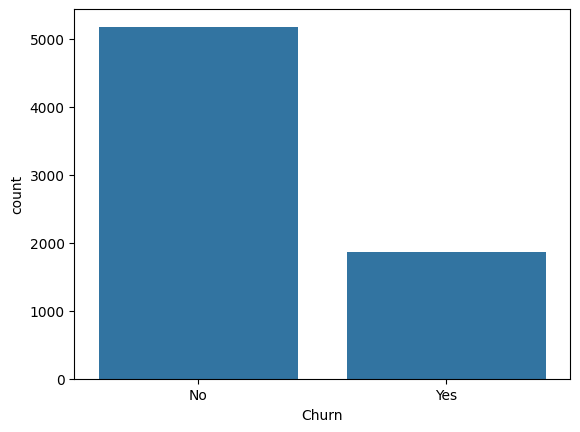

In [5]:
sns.countplot(x="Churn", data=df)
plt.show()

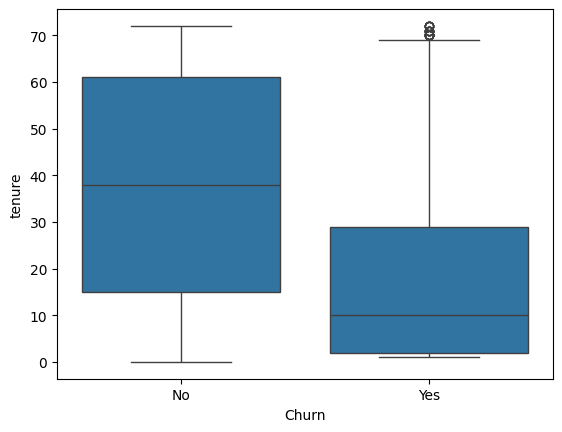

In [6]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.show()

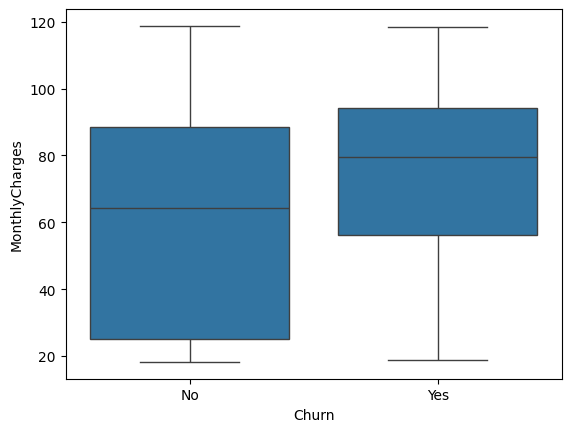

In [7]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.show()

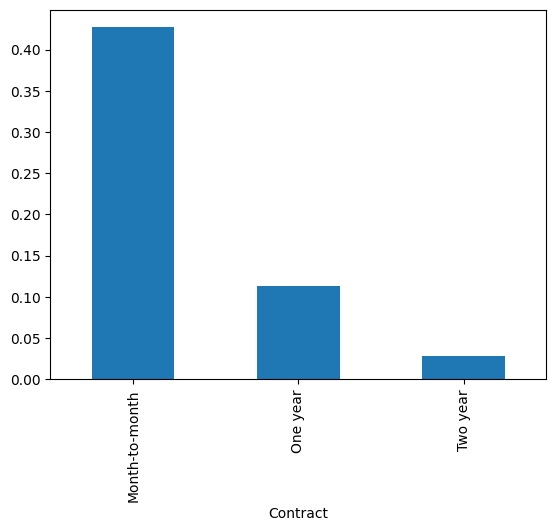

In [8]:
df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).plot.bar()
plt.show()

## Cleaning

In [9]:
df = df.drop(columns="customerID", errors="ignore")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
if df["Churn"].dtype == object:
    df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

## Features and split

In [10]:
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True, dtype=int)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Models

### Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]

results["Logistic Regression"] = [accuracy_score(y_test, lr_pred), precision_score(y_test, lr_pred),
                                  recall_score(y_test, lr_pred), f1_score(y_test, lr_pred),
                                  roc_auc_score(y_test, lr_proba)]

### KNN

In [12]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)
knn_proba = knn.predict_proba(X_test)[:, 1]

results["KNN"] = [accuracy_score(y_test, knn_pred), precision_score(y_test, knn_pred),
                  recall_score(y_test, knn_pred), f1_score(y_test, knn_pred),
                  roc_auc_score(y_test, knn_proba)]

### Naive Bayes

In [13]:
from sklearn.naive_bayes import GaussianNB

nb = make_pipeline(StandardScaler(), GaussianNB())
nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)
nb_proba = nb.predict_proba(X_test)[:, 1]

results["Naive Bayes"] = [accuracy_score(y_test, nb_pred), precision_score(y_test, nb_pred),
                          recall_score(y_test, nb_pred), f1_score(y_test, nb_pred),
                          roc_auc_score(y_test, nb_proba)]

### Decision Tree

In [14]:
from sklearn.tree import DecisionTreeClassifier

dt = make_pipeline(StandardScaler(),
                   DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
dt_proba = dt.predict_proba(X_test)[:, 1]

results["Decision Tree"] = [accuracy_score(y_test, dt_pred), precision_score(y_test, dt_pred),
                            recall_score(y_test, dt_pred), f1_score(y_test, dt_pred),
                            roc_auc_score(y_test, dt_proba)]

### Random Forest

In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = make_pipeline(StandardScaler(),
                   RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42))
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

results["Random Forest"] = [accuracy_score(y_test, rf_pred), precision_score(y_test, rf_pred),
                            recall_score(y_test, rf_pred), f1_score(y_test, rf_pred),
                            roc_auc_score(y_test, rf_proba)]

### SVM

In [16]:
from sklearn.svm import SVC

svm = make_pipeline(StandardScaler(),
                    SVC(probability=True, class_weight="balanced", random_state=42))
svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)
svm_proba = svm.predict_proba(X_test)[:, 1]

results["SVM"] = [accuracy_score(y_test, svm_pred), precision_score(y_test, svm_pred),
                  recall_score(y_test, svm_pred), f1_score(y_test, svm_pred),
                  roc_auc_score(y_test, svm_proba)]

### AdaBoost

In [17]:
from sklearn.ensemble import AdaBoostClassifier

ada = make_pipeline(StandardScaler(), AdaBoostClassifier(n_estimators=200, random_state=42))
ada.fit(X_train, y_train)

ada_pred = ada.predict(X_test)
ada_proba = ada.predict_proba(X_test)[:, 1]

results["AdaBoost"] = [accuracy_score(y_test, ada_pred), precision_score(y_test, ada_pred),
                       recall_score(y_test, ada_pred), f1_score(y_test, ada_pred),
                       roc_auc_score(y_test, ada_proba)]


### Gradient Boosting

In [18]:
from sklearn.ensemble import GradientBoostingClassifier

gb = make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=42))
gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)
gb_proba = gb.predict_proba(X_test)[:, 1]

results["Gradient Boosting"] = [accuracy_score(y_test, gb_pred), precision_score(y_test, gb_pred),
                                recall_score(y_test, gb_pred), f1_score(y_test, gb_pred),
                                roc_auc_score(y_test, gb_proba)]

### XGBoost

In [19]:
from xgboost import XGBClassifier

xgb = make_pipeline(StandardScaler(),
                    XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                  eval_metric="logloss", random_state=42))
xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

results["XGBoost"] = [accuracy_score(y_test, xgb_pred), precision_score(y_test, xgb_pred),
                      recall_score(y_test, xgb_pred), f1_score(y_test, xgb_pred),
                      roc_auc_score(y_test, xgb_proba)]

## Comparison

In [20]:
pd.DataFrame(results, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).T.round(3).sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
AdaBoost,0.805,0.669,0.524,0.588,0.843
Gradient Boosting,0.798,0.653,0.513,0.575,0.842
Logistic Regression,0.739,0.505,0.781,0.613,0.841
XGBoost,0.799,0.651,0.524,0.581,0.841
Decision Tree,0.735,0.500,0.807,0.618,0.831
Random Forest,0.789,0.628,0.500,0.557,0.824
SVM,0.747,0.516,0.767,0.617,0.819
Naive Bayes,0.656,0.427,0.866,0.572,0.809
KNN,0.774,0.577,0.551,0.564,0.807


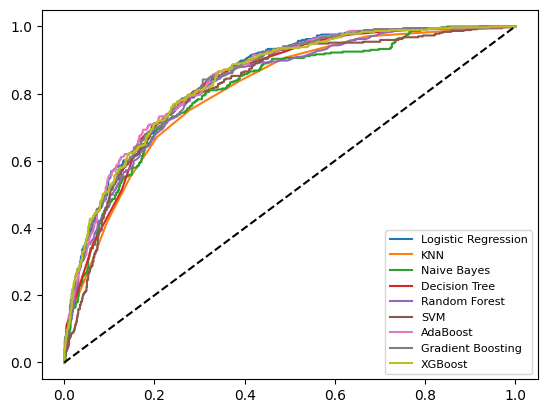

In [21]:
fpr, tpr, _ = roc_curve(y_test, lr_proba)
plt.plot(fpr, tpr, label="Logistic Regression")

fpr, tpr, _ = roc_curve(y_test, knn_proba)
plt.plot(fpr, tpr, label="KNN")

fpr, tpr, _ = roc_curve(y_test, nb_proba)
plt.plot(fpr, tpr, label="Naive Bayes")

fpr, tpr, _ = roc_curve(y_test, dt_proba)
plt.plot(fpr, tpr, label="Decision Tree")

fpr, tpr, _ = roc_curve(y_test, rf_proba)
plt.plot(fpr, tpr, label="Random Forest")

fpr, tpr, _ = roc_curve(y_test, svm_proba)
plt.plot(fpr, tpr, label="SVM")

fpr, tpr, _ = roc_curve(y_test, ada_proba)
plt.plot(fpr, tpr, label="AdaBoost")

fpr, tpr, _ = roc_curve(y_test, gb_proba)
plt.plot(fpr, tpr, label="Gradient Boosting")

fpr, tpr, _ = roc_curve(y_test, xgb_proba)
plt.plot(fpr, tpr, label="XGBoost")

plt.plot([0, 1], [0, 1], "k--")
plt.legend(fontsize=8)
plt.show()

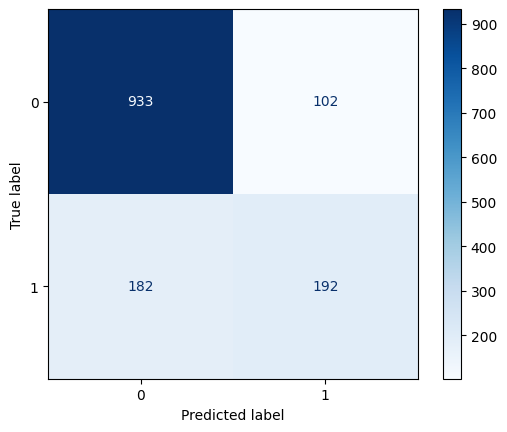

In [22]:
ConfusionMatrixDisplay.from_estimator(gb, X_test, y_test, cmap="Blues")
plt.show()

## Tuning Gradient Boosting

In [23]:
params = {
    "gradientboostingclassifier__n_estimators": [100, 200, 300],
    "gradientboostingclassifier__learning_rate": [0.03, 0.05, 0.1],
    "gradientboostingclassifier__max_depth": [2, 3, 4],
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=42)),
                    params, cv=skf, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

grid.best_params_

{'gradientboostingclassifier__learning_rate': 0.1,
 'gradientboostingclassifier__max_depth': 2,
 'gradientboostingclassifier__n_estimators': 100}

In [24]:
roc_auc_score(y_test, grid.predict_proba(X_test)[:, 1])

np.float64(0.8454790875506989)

## Save model

In [25]:
joblib.dump(grid.best_estimator_, "churn_best_model.joblib")

['churn_best_model.joblib']

In [26]:
   joblib.dump(X.columns.tolist(), "churn_columns.joblib")

['churn_columns.joblib']